# Antenna module

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from osi_hfss import decode, modules
from osi_hfss.data import load
from osi_hfss import modules
from osi_hfss.messages import preview
from osi_hfss.plots import plot_array

antenna_config = load("front.antenna.json")
antenna = modules.antenna_model(antenna_config)
tx, rx = decode.elements(antenna, decode.TRANSMIT), decode.elements(antenna, decode.RECEIVE)
f = antenna.element_type[0].frequency_instance[0].frequency
print(f"front radar: {len(tx)} Tx x {len(rx)} Rx MIMO at {f / 1e9:.2f} GHz, "
      f"{len(antenna.element_type)} element types for {len(antenna.element)} elements")

front radar: 3 Tx x 4 Rx MIMO at 76.75 GHz, 7 element types for 7 elements


## Element types: one Tx and one Rx element type

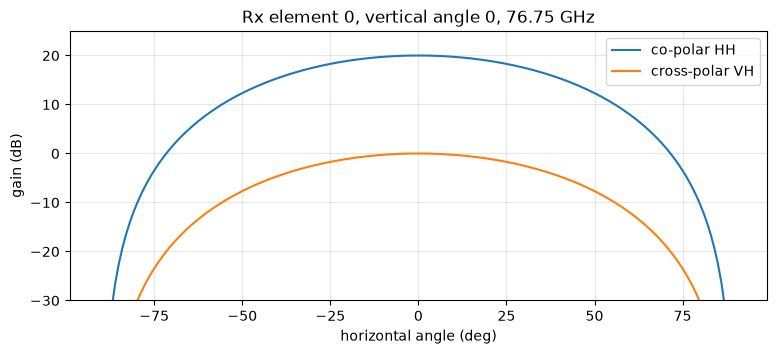

In [2]:
instance = decode.closest_frequency_instance(decode.element_type(antenna, rx[0]), f)
h = np.array(instance.radiation.horizontal_angle)
v0 = int(np.argmin(np.abs(np.array(instance.radiation.vertical_angle))))
gain = 10 ** (instance.gain / 20)

fig, ax = plt.subplots(figsize=(9, 3.5))
for name, label in (("pattern_00", "co-polar HH"), ("pattern_10", "cross-polar VH")):
    amplitude = np.abs(decode.pattern_grid(instance.radiation, name)[:, v0]) * gain
    ax.plot(np.degrees(h), 20 * np.log10(np.maximum(amplitude, 1e-6)), label=label)
ax.set_ylim(-30, 25); ax.set_xlabel("horizontal angle (deg)"); ax.set_ylabel("gain (dB)")
ax.set_title(f"Rx element 0, vertical angle 0, {f / 1e9:.2f} GHz"); ax.grid(True, alpha=0.3); ax.legend(); plt.show()

## Element positions

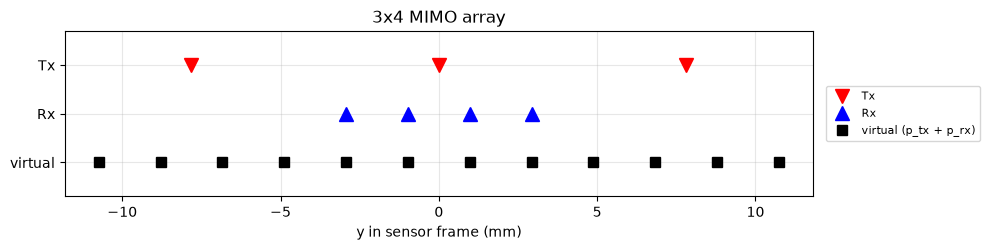

In [3]:
plot_array(antenna, f"{len(tx)}x{len(rx)} MIMO array")
plt.show()

## Embedded element patterns

In a real array every element sees its neighbours (mutual coupling), so each element has its own
**embedded pattern**.

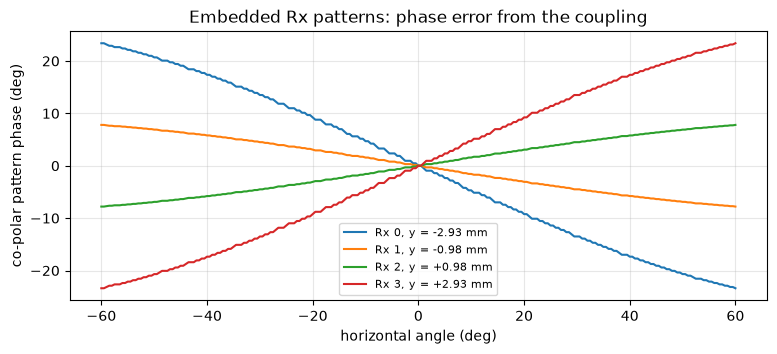

In [4]:
angles = np.radians(np.linspace(-60, 60, 241))

fig, ax = plt.subplots(figsize=(9, 3.5))
for e in rx:
    phase = np.angle(decode.element_jones(antenna, e, f, angles)[:, 0, 0])
    ax.plot(np.degrees(angles), np.degrees(phase), label=f"Rx {e.index}, y = {e.position.y * 1e3:+.2f} mm")
ax.set_xlabel("horizontal angle (deg)"); ax.set_ylabel("co-polar pattern phase (deg)")
ax.set_title("Embedded Rx patterns: phase error from the coupling"); ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
plt.show()

## The output, OSI `AntennaModel`

In [5]:
print(f"AntennaModel: {antenna.ByteSize() / 1e6:.2f} MB\n")
print(preview(antenna, max_repeated=1))

AntennaModel: 14.70 MB

id {
  value: 0
}
polarization_basis: POLARIZATION_BASIS_LINEAR_HV
element_type {
  id {
    value: 0
  }
  mode: MODE_TRANSMIT
  frequency_instance {
    frequency: 7.675e+10
    gain: 20
    phase: 0
    radiation {
      horizontal_angle: -1.5708
      horizontal_angle: ... 180 more
      vertical_angle: -1.5708
      vertical_angle: ... 180 more
      pattern_00 {
        amplitude: 1.4058e-65
        amplitude: ... 32760 more
        phase: 1.25664
        phase: ... 32760 more
      }
      pattern_11 {
        amplitude: 0
        amplitude: ... 32760 more
        phase: 1.25664
        phase: ... 32760 more
      }
      pattern_01 {
        amplitude: 1.4058e-66
        amplitude: ... 32760 more
        phase: 1.25664
        phase: ... 32760 more
      }
      pattern_10 {
        amplitude: 1.4058e-66
        amplitude: ... 32760 more
        phase: 1.25664
        phase: ... 32760 more
      }
    }
  }
}
element_type: ... 6 more
element {
  index: 0